In [1]:
import numpy as np
import torch

np_rng = np.random.default_rng(seed=1)
torch_rng = torch.Generator()
torch_rng.manual_seed(1)

num_sample_per_class = 1000

negative_sample = np_rng.multivariate_normal(
    mean=[0.0, 3.0],
    cov=[
        [1.0, 0.5],
        [0.5, 1.0],
    ],
    size=num_sample_per_class,
)
positive_sample = np_rng.multivariate_normal(
    mean=[3.0, 0.0],
    cov=[
        [1.0, 0.5],
        [0.5, 1.0],
    ],
    size=num_sample_per_class,
)

inputs_np = np.vstack((negative_sample, positive_sample), dtype="float32")
targets_np = np.vstack(
    (
        np.zeros((num_sample_per_class, 1)),
        np.ones((num_sample_per_class, 1)),
    ),
    dtype="float32",
)

inputs = torch.from_numpy(inputs_np)
targets = torch.from_numpy(targets_np)

print(f"{inputs.shape=}")
print(f"{targets.shape=}")

inputs.shape=torch.Size([2000, 2])
targets.shape=torch.Size([2000, 1])


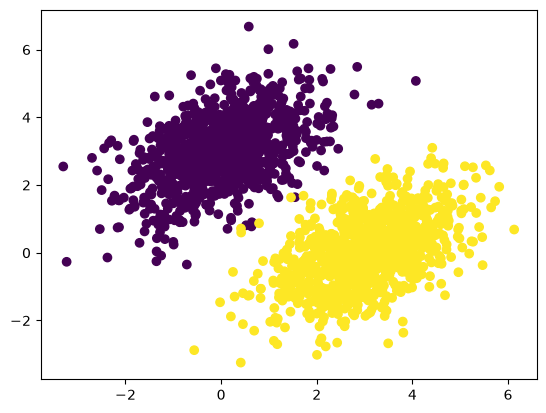

In [2]:
import matplotlib.pyplot as plt

plt.scatter(inputs[:, 0], inputs[:, 1], c=targets[:, 0] > 0.5)
plt.show()

In [3]:
input_dim, output_dim = 2, 1


class LinearModel(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.W = torch.nn.Parameter(
            torch.rand((input_dim, output_dim), generator=torch_rng)
        )
        self.b = torch.nn.Parameter(torch.zeros(output_dim))

    def forward(self, inputs):
        return torch.matmul(inputs, self.W) + self.b

model = LinearModel()
compiled_model = torch.compile(model)

In [4]:
learning_rate = 0.1
optimizer = torch.optim.SGD(compiled_model.parameters(), lr=learning_rate)

In [5]:
def mean_squared_error(targets, predictions):
    return torch.mean(torch.square(targets - predictions))

In [6]:
def training_step(inputs, targets):
    predictions = compiled_model(inputs)
    loss = mean_squared_error(targets, predictions)
    loss.backward()
    optimizer.step()
    compiled_model.zero_grad()
    return loss

In [7]:
for step in range(40):
    loss = training_step(inputs, targets)
    print(f"Loss at step {step}: {loss:.4f}")

Loss at step 0: 2.0420
Loss at step 1: 0.3786
Loss at step 2: 0.1530
Loss at step 3: 0.1150
Loss at step 4: 0.1035
Loss at step 5: 0.0963
Loss at step 6: 0.0902
Loss at step 7: 0.0846
Loss at step 8: 0.0795
Loss at step 9: 0.0749
Loss at step 10: 0.0706
Loss at step 11: 0.0667
Loss at step 12: 0.0632
Loss at step 13: 0.0599
Loss at step 14: 0.0570
Loss at step 15: 0.0543
Loss at step 16: 0.0518
Loss at step 17: 0.0495
Loss at step 18: 0.0474
Loss at step 19: 0.0455
Loss at step 20: 0.0438
Loss at step 21: 0.0422
Loss at step 22: 0.0408
Loss at step 23: 0.0394
Loss at step 24: 0.0382
Loss at step 25: 0.0371
Loss at step 26: 0.0361
Loss at step 27: 0.0352
Loss at step 28: 0.0343
Loss at step 29: 0.0336
Loss at step 30: 0.0328
Loss at step 31: 0.0322
Loss at step 32: 0.0316
Loss at step 33: 0.0311
Loss at step 34: 0.0306
Loss at step 35: 0.0301
Loss at step 36: 0.0297
Loss at step 37: 0.0293
Loss at step 38: 0.0290
Loss at step 39: 0.0287


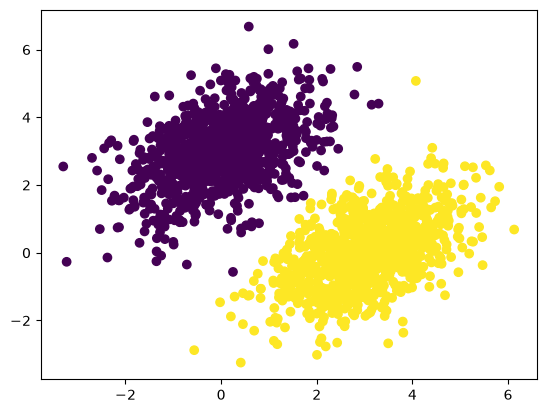

In [8]:
predictions = compiled_model(inputs)
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)
plt.show()